# Supervised Learning & Model Engineering - Group project
# STEP 2: Feature engineering (cleaning, missing values, encoding, engineered features)

**Dataset:** Adult / Census Income (OpenML, `name="adult"`, `version=2`)
**Group:** Clément, Eliott Monneraie, Lucas Stefani (lead for this step: Eliott, reviewed by all)
**Course reference:** Session 5 (Pipeline, ColumnTransformer), Session 2 (scaling for regularised models), Session 1 (leakage)
**Code:** `src/features.py` (settings in `config.yaml`, section `features`; tests in `tests/test_features.py`). This notebook only calls the code, shows what it does and justifies each choice with numbers.

### How to read this notebook
Same labels as STEP 1: **What we see**, **What we decide**, **What could invalidate it**, **Note for STEP X**, **Limitation**.

### The rule of this step
Development set only (from `src.data.load_splits`). Every transformation that learns from data (median, list of categories, mean and standard deviation) sits **inside the Pipeline**, so in cross-validation it is refitted on the 4 training folds and never sees the validation fold.

### How to run
From the project root, after `python -m src.data`. Runtime: under one minute.

In [1]:
# ===================== Setup =====================
import os, sys, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_validate

# Run from the project root (works from notebooks/ too), so that src/ and config.yaml are found.
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())
from src.data import load_config, load_splits, get_cv
from src.features import AdultFeatureBuilder, build_preprocessor, CATEGORICAL_COLUMNS

warnings.filterwarnings("ignore", message="Unknown solver options")   # harmless scipy/sklearn notice
cfg = load_config()
FIG_DIR = cfg["paths"]["figures_dir"]
os.makedirs(FIG_DIR, exist_ok=True)
sns.set_theme(style="whitegrid")
COLORS = {"<=50K": "#8da0cb", ">50K": "#fc8d62"}

def savefig(name: str) -> None:
    path = os.path.join(FIG_DIR, f"{name}.png")
    plt.tight_layout(); plt.savefig(path, dpi=150, bbox_inches="tight")
    print(f"Figure saved: {path}")

# Development set only. The test set is read by load_splits but never used here.
X_dev, _, y_dev, _ = load_splits(cfg)
cv = get_cv(cfg)
prevalence = y_dev.mean()
print(f"Development set: {X_dev.shape[0]} rows x {X_dev.shape[1]} raw columns, prevalence = {prevalence:.2%}")

Development set: 39032 rows x 14 raw columns, prevalence = 23.94%


---
# Part A - Where each transformation lives

| Kind | Examples | Learns from data? | Where |
|---|---|---|---|
| **Stateless** (row by row) | drop `fnlwgt`, `education`, `sex`, `race`; `Husband`/`Wife` -> `Spouse`; capital indicators; age and hours bands | No | `AdultFeatureBuilder`, first step of the Pipeline |
| **Learned** | median imputation; list of categories and of rare categories; mean and std for scaling | Yes | `ColumnTransformer`, second step, fitted on training folds only |

Two preprocessors, because the model families of STEP 4 need different inputs:
- `family="linear"` (logistic regression): one-hot, scaling, plus the age and hours bands. A linear model cannot cut a variable into ranges by itself.
- `family="tree"` (random forest, gradient boosting): ordinal codes, no scaling, no bands. Trees find their own cut points.

```
raw row (14 columns, as saved by src/data.py)
  -> AdultFeatureBuilder   drop 4 columns + capital amounts, recode relationship, add engineered features
  -> ColumnTransformer
       numbers     -> median imputer -> StandardScaler (linear only)
       categories  -> "Missing" imputer -> OneHotEncoder (linear) / OrdinalEncoder (tree)
  -> model (STEP 4)
```
The `capital` option (`indicators` by default, `amounts`, `none`) exists so that STEP 6 can rebuild the "exact amounts" reference model of decision 7 with the **same** code.

In [2]:
# ===================== A.2 What the builder does to three real rows =====================
builder = AdultFeatureBuilder(capital=cfg["features"]["capital"]).fit(X_dev)
X_built = builder.transform(X_dev)
print("Raw columns   :", list(X_dev.columns))
print("After builder :", list(X_built.columns))
print("\nRemoved:", sorted(set(X_dev.columns) - set(X_built.columns)))
print("Added  :", [c for c in X_built.columns if c not in X_dev.columns])
idx = X_dev.sample(3, random_state=cfg["seed"]).index
display(X_dev.loc[idx, ["age", "relationship", "capital-gain", "capital-loss", "hours-per-week", "sex", "fnlwgt"]])
display(X_built.loc[idx, ["age", "age_band", "relationship", "has_capital_gain", "has_capital_loss",
                          "hours-per-week", "hours_band"]])

Raw columns   : ['age', 'workclass', 'fnlwgt', 'education', 'education-num', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'capital-gain', 'capital-loss', 'hours-per-week', 'native-country']
After builder : ['age', 'workclass', 'education-num', 'marital-status', 'occupation', 'relationship', 'hours-per-week', 'native-country', 'has_capital_gain', 'has_capital_loss', 'age_band', 'hours_band']

Removed: ['capital-gain', 'capital-loss', 'education', 'fnlwgt', 'race', 'sex']
Added  : ['has_capital_gain', 'has_capital_loss', 'age_band', 'hours_band']


,age,relationship,capital-gain,capital-loss,hours-per-week,sex,fnlwgt
12291,36,Not-in-family,0,0,45,Female,81896
14645,37,Husband,0,0,50,Male,112497
1006,66,Not-in-family,0,0,40,Male,271567


,age,age_band,relationship,has_capital_gain,has_capital_loss,hours-per-week,hours_band
12291,36,36-45,Not-in-family,0.0,0.0,45,41-49
14645,37,36-45,Spouse,0.0,0.0,50,50+
1006,66,66+,Not-in-family,0.0,0.0,40,35-40


**What we see.** 14 raw columns in, 12 out of the builder: 6 removed (`fnlwgt`, `education`, `sex`, `race`, and the two capital amounts), 4 added (`has_capital_gain`, `has_capital_loss`, `age_band`, `hours_band`). `Husband` now reads `Spouse`.

**What we decide.** `sex`, `race` and the capital amounts are removed **by the Pipeline itself**: no model can receive them, even if someone passes the full raw table. `sex` and `race` stay in `X_dev` / `X_test` for STEP 9.

---
# Part B - Cleaning decisions from STEP 1
## B.1 `relationship`: `Husband` + `Wife` -> `Spouse` (decision 9)

In [3]:
# ===================== B.1 relationship: Husband + Wife -> Spouse =====================
def rate_table(s: pd.Series) -> pd.DataFrame:
    return (y_dev.groupby(s.astype(str)).agg(["mean", "size"])
            .rename(columns={"mean": ">50K rate", "size": "n"})
            .sort_values(">50K rate", ascending=False))

fmt = {">50K rate": "{:.1%}"}
print("Before (raw):");      display(rate_table(X_dev["relationship"]).style.format(fmt))
print("After (recoded):");   display(rate_table(X_built["relationship"]).style.format(fmt))
women = (X_dev["sex"].astype(str) == "Female").groupby(X_built["relationship"]).mean()
print("Share of women per recoded category:"); display(women.sort_values(ascending=False).map("{:.1%}".format))

Before (raw):


,>50K rate,n
relationship,,
Wife,46.0%,1852
Husband,44.9%,15777
Not-in-family,10.3%,10009
Unmarried,5.9%,4106
Other-relative,3.4%,1205
Own-child,1.4%,6083


After (recoded):


,>50K rate,n
relationship,,
Spouse,45.1%,17629
Not-in-family,10.3%,10009
Unmarried,5.9%,4106
Other-relative,3.4%,1205
Own-child,1.4%,6083


Share of women per recoded category:


relationship
Unmarried         76.3%
Not-in-family     46.1%
Other-relative    45.6%
Own-child         44.3%
Spouse            10.5%
Name: sex, dtype: object

**What we see.** `Wife` (46.0%) and `Husband` (44.9%) have almost the same rate on the development set. `Spouse` (17,629 people) has 45.1%: the household-role signal is kept.

**Limitation.** The sex proxy is reduced, not removed: `Unmarried` is still 76.3% women, `Spouse` 10.5% women (89% of married people in the data are men). STEP 9 measures the remaining effect on the model's decisions.

## B.2 Columns dropped (decisions 3, 4, 7, 8)
Shown in A.2: `fnlwgt`, `education`, `sex`, `race`, and the two capital amounts (replaced by indicators, Part E.1).

---
# Part C - Missing values

In [4]:
# ===================== C. Missing values =====================
na = X_dev.isna()
display(pd.DataFrame({"n missing": na.sum(), "% missing": (na.mean() * 100).round(2)}).query("`n missing` > 0"))
rows = [{"column": c, ">50K if Missing": y_dev[X_dev[c].isna()].mean(),
         ">50K if filled in": y_dev[X_dev[c].notna()].mean()} for c in ["workclass", "occupation", "native-country"]]
display(pd.DataFrame(rows).set_index("column").style.format("{:.1%}"))

pre_lin = build_preprocessor(cfg, family="linear").fit(X_dev)
Xt_lin = pd.DataFrame(pre_lin.transform(X_dev), columns=pre_lin.get_feature_names_out(), index=X_dev.index)
print("NaN left after preprocessing:", int(Xt_lin.isna().sum().sum()))
print("'Missing' columns created:", [c for c in Xt_lin.columns if c.endswith("_Missing")])

,n missing,% missing
workclass,2218,5.68
occupation,2226,5.70
native-country,671,1.72


,>50K if Missing,>50K if filled in
column,,
workclass,9.5%,24.8%
occupation,9.5%,24.8%
native-country,26.1%,23.9%


NaN left after preprocessing: 0
'Missing' columns created: ['workclass_Missing', 'occupation_Missing', 'native-country_Missing']


**What we see.** Missing values only in `workclass` (5.7%), `occupation` (5.7%), `native-country` (1.7%). For the first two, missing means 9.5% >50K vs 24.8%. After preprocessing: 0 NaN, and three explicit `*_Missing` columns.

**What we decide.**
1. **Categorical: `"Missing"` is a category of its own** (decision 5). Filling with the most frequent value (`Private`) would merge people outside employment with private employees and erase a 15-point difference.
2. **Numerical: median imputer as a safeguard.** No numeric value is missing today, but a production row could arrive incomplete. Without an imputer the Pipeline would crash on it. The median is learned on the training folds.

**What could invalidate it.** If missing values appeared in production for another reason (a form bug), `"Missing"` would carry the wrong meaning: its share should be monitored.

---
# Part D - Encoding categorical variables

In [5]:
# ===================== D. Encoding: what the encoders learned on the development set =====================
ct = pre_lin.named_steps["encode"]
ohe = ct.named_transformers_["cat"].named_steps["encode"]
cat_in = ct.transformers_[1][2]
rows = []
for col, cats, infreq in zip(cat_in, ohe.categories_, ohe.infrequent_categories_):
    infreq = [] if infreq is None else list(infreq)
    rows.append({"column": col, "categories seen": len(cats), "grouped (<0.5%)": len(infreq),
                 "one-hot columns": len(cats) - len(infreq) + (1 if infreq else 0),
                 "grouped values": ", ".join(infreq[:4]) + (" ..." if len(infreq) > 4 else "")})
display(pd.DataFrame(rows).set_index("column"))
nc = list(ohe.infrequent_categories_[cat_in.index("native-country")])
print(f"native-country: {len(nc)} countries grouped, {X_dev['native-country'].isin(nc).mean():.1%} of rows")

pre_tree = build_preprocessor(cfg, family="tree").fit(X_dev)
print(f"\nWidth of the model input: linear = {len(pre_lin.get_feature_names_out())} columns, "
      f"tree = {len(pre_tree.get_feature_names_out())} columns")
print("Tree inputs:", list(pre_tree.get_feature_names_out()))

new_person = X_dev.iloc[[0]].copy()
new_person["native-country"] = new_person["native-country"].astype(object)
new_person.loc[:, "native-country"] = "Atlantis"
print("\nUnknown country -> linear:", pre_lin.transform(new_person).shape, "| tree:", pre_tree.transform(new_person).shape)

,categories seen,grouped (<0.5%),one-hot columns,grouped values
column,,,,
workclass,9,2,8,"Never-worked, Without-pay"
marital-status,7,1,7,Married-AF-spouse
occupation,15,2,14,"Armed-Forces, Priv-house-serv"
relationship,5,0,5,
native-country,42,38,5,"Cambodia, Canada, China, Columbia ..."
age_band,6,0,6,
hours_band,4,0,4,


native-country: 38 countries grouped, 5.9% of rows

Width of the model input: linear = 54 columns, tree = 10 columns
Tree inputs: ['age', 'education-num', 'hours-per-week', 'has_capital_gain', 'has_capital_loss', 'workclass', 'marital-status', 'occupation', 'relationship', 'native-country']

Unknown country -> linear: (1, 54) | tree: (1, 10)


**What we see.** `native-country`: 38 of 42 values (including `Missing`) are below 0.5% of rows, 5.9% of people together; only `United-States`, `Mexico`, `Philippines` and `Missing` keep their own column. A few rare values are also grouped in `workclass` (`Never-worked`, `Without-pay`), `marital-status` (`Married-AF-spouse`) and `occupation` (`Armed-Forces`, `Priv-house-serv`). Linear input: 54 columns; tree input: 10 columns. A country never seen in training passes through both.

**What we decide.**
1. **Linear: one-hot.** These categories have no order; codes 1, 2, 3 would impose a fake ranking on a linear model.
2. **Rare categories (< 0.5% of training rows) grouped** into one `infrequent` column (threshold from STEP 1). A coefficient estimated on 20 people is noise. The list is learned on the training folds.
3. **Unknown category at prediction time** -> `infrequent` column (linear) or code -1 (tree), instead of an error.
4. **Trees: ordinal codes**, one column per variable. For `HistGradientBoostingClassifier`, `categorical_mask()` tells the model which columns are categorical, so the codes are not treated as ordered.
5. **`education-num` stays numeric**: its order is real (STEP 1).
6. **No target encoding**: it puts the target inside the features and needs out-of-fold fitting to avoid leakage. With at most 42 values, one-hot is affordable and simpler to defend.

---
# Part E - Engineered features
The project asks for at least 2-3 justified features. We create **four**: two capital indicators (decided in STEP 1, D.1) and two bands for the linear model. Part F checks that each one improves the cross-validated score.

## E.1 `has_capital_gain`, `has_capital_loss`

,share = 1,>50K if 1,>50K if 0
feature,,,
has_capital_gain,8.2%,61.4%,20.6%
has_capital_loss,4.6%,50.0%,22.7%


People with both a gain and a loss: 0
People with capital-gain = 99999 -> has_capital_gain = 1: 100%


Figure saved: reports/figures/08_capital_indicators.png


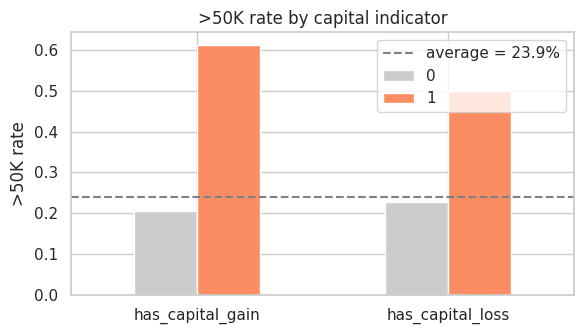

In [6]:
# ===================== E.1 Capital indicators =====================
rows = []
for flag, raw in [("has_capital_gain", "capital-gain"), ("has_capital_loss", "capital-loss")]:
    on = X_dev[raw] > 0
    rows.append({"feature": flag, "share = 1": on.mean(),
                 ">50K if 1": y_dev[on].mean(), ">50K if 0": y_dev[~on].mean()})
display(pd.DataFrame(rows).set_index("feature").style.format("{:.1%}"))
both = ((X_dev["capital-gain"] > 0) & (X_dev["capital-loss"] > 0)).sum()
print(f"People with both a gain and a loss: {both}")
print(f"People with capital-gain = 99999 -> has_capital_gain = 1: "
      f"{X_built.loc[X_dev['capital-gain'] == 99999, 'has_capital_gain'].eq(1).mean():.0%}")

t = pd.DataFrame({"has_capital_gain": y_dev.groupby(X_dev["capital-gain"] > 0).mean(),
                  "has_capital_loss": y_dev.groupby(X_dev["capital-loss"] > 0).mean()}).T
t.columns = ["0", "1"]
fig, ax = plt.subplots(figsize=(6, 3.5))
t.plot.bar(ax=ax, color=["#cccccc", COLORS[">50K"]], rot=0)
ax.axhline(prevalence, ls="--", color="grey", label=f"average = {prevalence:.1%}")
ax.set_title(">50K rate by capital indicator"); ax.set_ylabel(">50K rate"); ax.legend()
savefig("08_capital_indicators")
plt.show()

**What we see.** 8.2% of people have a capital gain and 4.6% a capital loss, never both. Having one is a strong signal: 61.4% >50K with a gain (vs 20.6%), 50.0% with a loss (vs 22.7%). The 244 people at 99,999 all get `has_capital_gain = 1`.

**What we decide.** The amounts are replaced by these two indicators (STEP 1, decision 7): the legitimate information is "this person holds and trades investments"; the exact amounts behave like codes and are not known at prediction time. Two separate flags, not a single `net_capital = gain - loss`: a loss is a sign of wealth too (50.0% >50K), and a net value would push those people towards low income.

**Note for STEP 6.** `build_preprocessor(cfg, family, capital="amounts")` rebuilds the reference model with the exact amounts (log1p for the linear model, raw for trees), to report the cost of decision 7.

## E.2 and E.3 `age_band` and `hours_band` (linear model only)

,>50K rate,n
age_band,,
17-25,1.6%,7689
26-35,18.9%,10235
36-45,34.4%,9542
46-55,39.8%,6615
56-65,31.0%,3532
66+,19.6%,1419


,>50K rate,n
hours_band,,
<35,6.6%,6649
35-40,20.6%,20826
41-49,34.8%,3763
50+,42.5%,7794


Figure saved: reports/figures/09_age_hours_bands.png


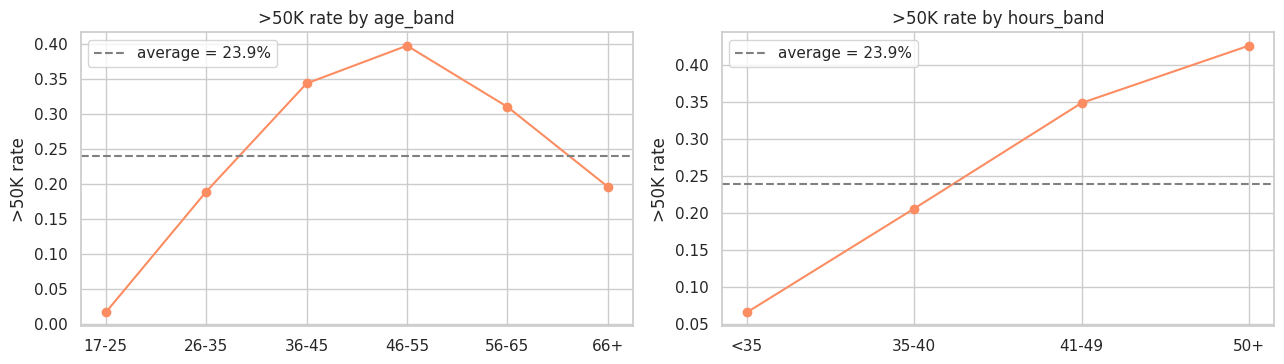

In [7]:
# ===================== E.2 / E.3 Age bands and hours bands =====================
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for ax, col, labels in [(axes[0], "age_band", cfg["features"]["age_labels"]),
                        (axes[1], "hours_band", cfg["features"]["hours_labels"])]:
    t = y_dev.groupby(X_built[col]).agg(["mean", "size"]).loc[labels]
    ax.plot(t.index, t["mean"], marker="o", color=COLORS[">50K"])
    ax.axhline(prevalence, ls="--", color="grey", label=f"average = {prevalence:.1%}")
    ax.set_title(f">50K rate by {col}"); ax.set_ylabel(">50K rate"); ax.legend()
    display(t.rename(columns={"mean": ">50K rate", "size": "n"}).style.format({">50K rate": "{:.1%}"}))
savefig("09_age_hours_bands")
plt.show()

**What we see.** Age: 1.6% >50K at 17-25, peak 39.8% at 46-55, 19.6% after 65 (bell shape). Hours: 6.6% part-time, 20.6% standard week, 34.8% at 41-49, 42.5% at 50+ (steps, not a straight line).

**What we decide.**
1. **`age_band`** (6 bands, one-hot), **next to** the numeric `age`. One coefficient for `age` can say "older = richer", not "rises then falls".
2. **`hours_band`** (4 bands), **next to** `hours-per-week`. 46.7% of people work exactly 40 hours: the information is mostly part-time / standard / long hours.
3. Edges in `config.yaml`, chosen as round life stages and usual definitions (part-time below 35 hours), **not** optimised on the target.
4. Not given to trees, which can split `age` at 25 or 55 by themselves.

**What could invalidate it.** If the logistic regression still underfits age in STEP 4, a `SplineTransformer` (smooth curve) is the next option.

**Limitation.** The edges were chosen after the STEP 1 EDA, which used all rows. Round, domain-based edges limit this risk, and the shape is re-checked here on the development set only.

---
# Part F - Does each feature buy something?
Default logistic regression (no tuning: STEP 6), the STEP 1 folds (`get_cv`), PR-AUC. Each variant is a full Pipeline, so encoders and scaler are refitted on each training fold. We compare **inputs**, with the model fixed: this is not model selection.

,PR-AUC mean,PR-AUC std,ROC-AUC mean,gain vs line 1,gain vs line 2,folds better than '+ capital indicators'
variant,,,,,,
"no capital, no band",0.6882,0.0112,0.8839,-,-,-
+ capital indicators,0.7289,0.0095,0.8957,+0.0407,-,-
+ indicators + age_band,0.7397,0.0101,0.8996,+0.0515,+0.0108,5/5
+ indicators + hours_band,0.7360,0.0100,0.8976,+0.0478,+0.0071,5/5
+ indicators + both bands (kept),0.7449,0.0105,0.9011,+0.0567,+0.0160,5/5


Random baseline (prevalence) = 0.239
Figure saved: reports/figures/10_feature_ablation_per_fold.png


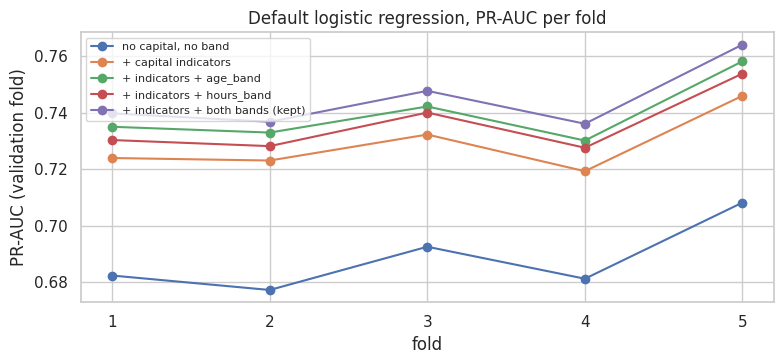

In [8]:
# ===================== F.1 Does each engineered feature buy something? =====================
variants = {
    "no capital, no band":            ("none", ()),
    "+ capital indicators":           ("indicators", ()),
    "+ indicators + age_band":        ("indicators", ("age_band",)),
    "+ indicators + hours_band":      ("indicators", ("hours_band",)),
    "+ indicators + both bands (kept)": ("indicators", ("age_band", "hours_band")),
}
rows, folds = [], {}
for name, (capital, bands) in variants.items():
    model = Pipeline([("pre", build_preprocessor(cfg, "linear", capital=capital, bands=bands)),
                      ("model", LogisticRegression(max_iter=2000))])
    s = cross_validate(model, X_dev, y_dev, cv=cv, scoring=["average_precision", "roc_auc"])
    folds[name] = s["test_average_precision"]
    rows.append({"variant": name, "PR-AUC mean": s["test_average_precision"].mean(),
                 "PR-AUC std": s["test_average_precision"].std(), "ROC-AUC mean": s["test_roc_auc"].mean()})
res = pd.DataFrame(rows).set_index("variant")
names = list(folds)
res["gain vs line 1"] = ["-"] + [f"{folds[n].mean() - folds[names[0]].mean():+.4f}" for n in names[1:]]
ref = folds["+ capital indicators"]
res["gain vs line 2"] = ["-", "-"] + [f"{folds[n].mean() - ref.mean():+.4f}" for n in names[2:]]
res["folds better than '+ capital indicators'"] = ["-", "-"] + [f"{int((folds[n] > ref).sum())}/5" for n in names[2:]]
display(res.style.format({"PR-AUC mean": "{:.4f}", "PR-AUC std": "{:.4f}", "ROC-AUC mean": "{:.4f}"}))
print(f"Random baseline (prevalence) = {prevalence:.3f}")

fig, ax = plt.subplots(figsize=(8, 3.8))
for n, v in folds.items():
    ax.plot(range(1, 6), v, marker="o", label=n)
ax.set_xticks(range(1, 6)); ax.set_xlabel("fold"); ax.set_ylabel("PR-AUC (validation fold)")
ax.set_title("Default logistic regression, PR-AUC per fold"); ax.legend(fontsize=8)
savefig("10_feature_ablation_per_fold")
plt.show()

**What we see.**
- Without capital information and bands: PR-AUC 0.688 (random baseline 0.239).
- **Capital indicators: +0.041** (0.729). Same direction as the tree check of STEP 1 (0.714 -> 0.748).
- **Age bands: +0.011**, **hours bands: +0.007**, both together **+0.016** (0.745), better than indicators alone on **5/5 folds**.
- Fold-to-fold std is about 0.010, but the comparison is paired (same folds for every variant): each band variant beats "indicators only" on every fold, so the gains are not a lucky split.

**What we decide.** We keep the four features. The linear reference for STEP 4 is **PR-AUC 0.745** (default logistic regression).

**Note for STEP 4.** Trees receive no bands. If a tree model beats 0.745 without them, it confirms they learn the shapes themselves.

## F.2 What the linear model learned from `age_band`

Figure saved: reports/figures/11_age_band_coefficients.png


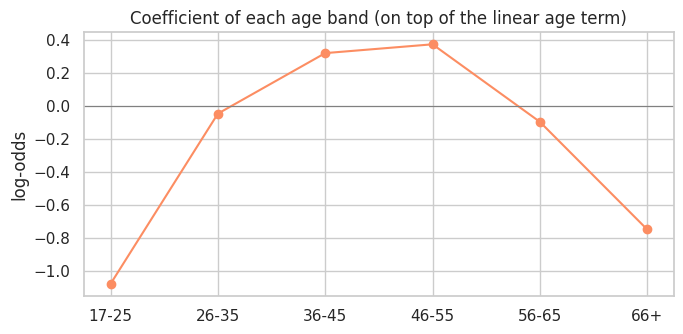

Linear 'age' coefficient (standardised): +0.317


In [9]:
# ===================== F.2 What the linear model learned from age_band =====================
model = Pipeline([("pre", build_preprocessor(cfg, "linear")),
                  ("model", LogisticRegression(max_iter=2000))]).fit(X_dev, y_dev)
coef = pd.Series(model.named_steps["model"].coef_[0], index=model.named_steps["pre"].get_feature_names_out())
age_coef = coef[[f"age_band_{b}" for b in cfg["features"]["age_labels"]]]
age_coef.index = cfg["features"]["age_labels"]
fig, ax = plt.subplots(figsize=(7, 3.5))
age_coef.plot(ax=ax, marker="o", color=COLORS[">50K"]); ax.axhline(0, color="grey", lw=0.8)
ax.set_title("Coefficient of each age band (on top of the linear age term)"); ax.set_ylabel("log-odds")
savefig("11_age_band_coefficients")
plt.show()
print(f"Linear 'age' coefficient (standardised): {coef['age']:+.3f}")
# Fitted on the whole development set only to READ the coefficients: no score is reported from it.

**What we see.** The band coefficients draw the bell curve: strongly negative at 17-25, highest at 36-55, negative again after 65. The single `age` coefficient could not represent this shape.

**What we decide.** The feature does what it was built for, and it stays readable for STEP 8.

---
# Part G - Decisions log for STEP 2 (copied into DECISIONS.md)

| # | Decision | Where |
|---|---|---|
| 12 | Two-layer Pipeline: stateless `AdultFeatureBuilder`, then learned `ColumnTransformer` fitted on training folds only | `src/features.py` |
| 13 | Two preprocessors: `linear` (one-hot, scaling, bands) and `tree` (ordinal codes, raw values, no bands) | `build_preprocessor(cfg, family)` |
| 14 | Missing categorical -> `"Missing"`; median imputer on numbers as a production safeguard | `ColumnTransformer` |
| 15 | One-hot for linear, categories < 0.5% grouped, unknown categories tolerated; ordinal for trees; no target encoding | `ColumnTransformer` |
| 16 | Engineered: `has_capital_gain`, `has_capital_loss` (all models); `age_band`, `hours_band` (linear only); no `net_capital` | `AdultFeatureBuilder`, `config.yaml` |
| 17 | `capital` option (`indicators` / `amounts` / `none`) to rebuild the STEP 6 reference with the same code | `config.yaml`, `build_preprocessor` |
| 18 | Evidence: default logistic regression 0.688 -> 0.729 (indicators) -> 0.745 (bands), 5/5 folds | this notebook, Part F |